In [1]:
import os
from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# Define dataset path (adjust if your PlantVillage folder is named differently)
DATA_DIR = Path(r"C:\Users\ACER\Intern21\smart-agriculture-platform\data\raw\PlantVillage") # Update relative path based on where your notebook lives

if not DATA_DIR.exists():
    # Fallback to absolute or alternative relative path check
    DATA_DIR = Path("data/raw/PlantVillage")
    
print(f"Target Dataset Directory: {DATA_DIR.resolve()}")

Target Dataset Directory: C:\Users\ACER\Intern21\smart-agriculture-platform\data\raw\PlantVillage


In [2]:
def audit_dataset(data_dir):
    class_counts = {}
    corrupted_images = []
    resolutions = []
    
    if not data_dir.exists():
        print(f"Error: Directory {data_dir} does not exist. Please check your data path.")
        return
        
    classes = [d for d in data_dir.iterdir() if d.is_dir()]
    print(f"Found {len(classes)} classes/folders.")
    
    for class_path in tqdm(classes, desc="Auditing Classes"):
        class_name = class_path.name
        images = list(class_path.glob("*.[jJ][pP][gG]")) + list(class_path.glob("*.[pP][nN][gG]"))
        class_counts[class_name] = len(images)
        
        for img_path in images:
            try:
                with Image.open(img_path) as img:
                    resolutions.append(img.size) # (width, height)
                    img.verify() # Verify integrity
            except Exception as e:
                corrupted_images.append((str(img_path), str(e)))
                
    return class_counts, corrupted_images, resolutions

# Run the audit
counts, corrupts, res = audit_dataset(DATA_DIR)

if counts:
    df_counts = pd.DataFrame(list(counts.items()), columns=['Class', 'Count']).sort_values(by='Count', ascending=False)
    print("\n--- Dataset Audit Summary ---")
    print(f"Total Images Scanned: {df_counts['Count'].sum():,}")
    print(f"Corrupted Images Found: {len(corrupts)}")
    display(df_counts.head(10))

Found 15 classes/folders.


Auditing Classes: 100%|██████████| 15/15 [00:40<00:00,  2.72s/it]


--- Dataset Audit Summary ---
Total Images Scanned: 20,634
Corrupted Images Found: 0


,Class,Count
14,Tomato__Tomato_YellowLeaf__Curl_Virus,3208
5,Tomato_Bacterial_spot,2127
8,Tomato_Late_blight,1908
10,Tomato_Septoria_leaf_spot,1771
11,Tomato_Spider_mites_Two_spotted_spider_mite,1676
7,Tomato_healthy,1590
1,Pepper__bell___healthy,1476
12,Tomato__Target_Spot,1404
2,Potato___Early_blight,1000
4,Potato___Late_blight,1000


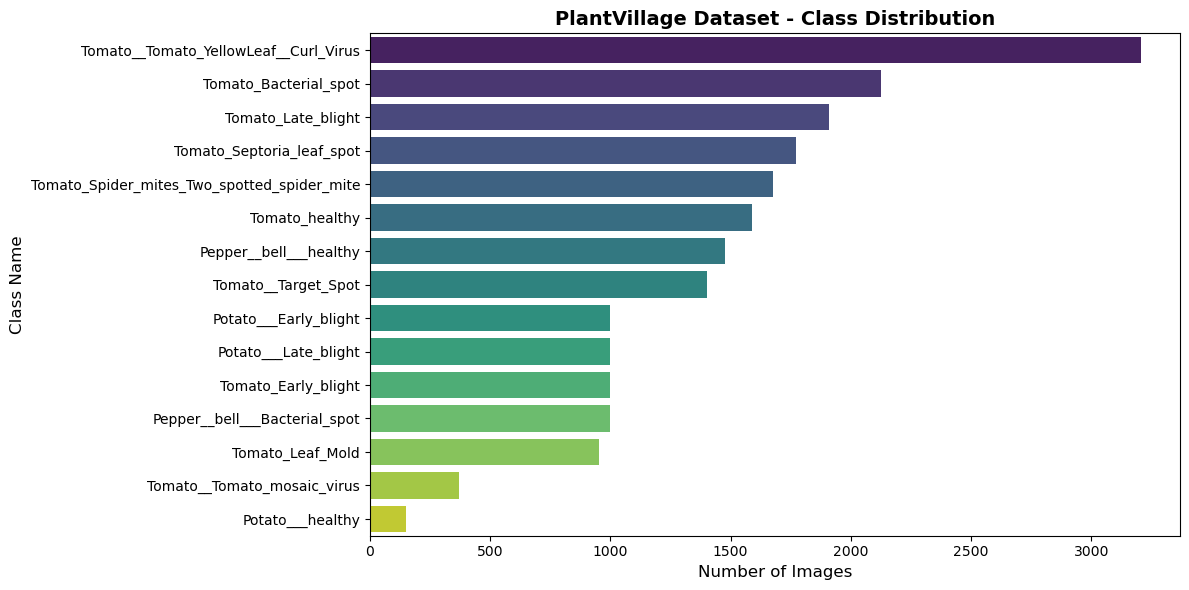


--- Resolution Profile ---
Min Dimensions: 256x256
Max Dimensions: 256x256
Most Common Resolution: (256, 256) (Width x Height)


In [3]:
# Cell: Visualize Class Distribution
plt.figure(figsize=(12, 6))
sns.barplot(data=df_counts, x='Count', y='Class', hue='Class', palette='viridis', legend=False)
plt.title('PlantVillage Dataset - Class Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Number of Images', fontsize=12)
plt.ylabel('Class Name', fontsize=12)
plt.tight_layout()
plt.show()

# Quick check on image resolutions
widths = [dim[0] for dim in res]
heights = [dim[1] for dim in res]
print(f"\n--- Resolution Profile ---")
print(f"Min Dimensions: {min(widths)}x{min(heights)}")
print(f"Max Dimensions: {max(widths)}x{max(heights)}")
print(f"Most Common Resolution: {pd.Series(res).mode()[0]} (Width x Height)")